# Aircraft engine remaining useful life prediction
## NASA C-MAPSS FD001 · CMPS 261 · Group 16
**Moustapha Haydoura · Wassim Fawaz · Mohamad Khalil**

Research question: does learning a temporal representation improve on a tuned classical model with the same historical information, and at what computational cost?

This final notebook preserves the original six-step workflow and includes the complete implementation. The notebook and final report use the same saved experiment artifacts.

### 1. Environment setup and complete implementation
Install `requirements.txt` in Python 3.14 (the tested environment). Run from the project root. The notebook embeds the complete pipeline and can restore its source file when the file is missing. Training uses four CPU threads, seeded random generators, deterministic PyTorch operations, and no GPU requirement. Set `RUN_TRAINING=True` to regenerate experiments; the default review mode loads the completed run.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
assert (ROOT/'train_FD001.txt').exists(), 'Run this notebook from the project folder.'
(ROOT/'src').mkdir(exist_ok=True)
RUN_TRAINING=False

In [2]:
pipeline_source = """\
\"""Reproducible FD001 experiments. No test targets enter fitting or selection.\"""
from __future__ import annotations

import argparse
import copy
import hashlib
import importlib.metadata
import json
import os
import platform
import random
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBRegressor

ROOT = Path(__file__).resolve().parents[1]
COLUMNS = ['unit_id', 'time_cycles'] + [f'op_setting_{i}' for i in range(1, 4)] + [f'sensor_{i}' for i in range(1, 22)]
# Sensor 6 is near-constant, not exactly constant; keep the original FD001 convention.
DROP = ['op_setting_3', 'sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
FEATURES = [c for c in COLUMNS[2:] if c not in DROP]
CAP = 125
WINDOW = 30
THREADS = 4


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(THREADS)
    torch.use_deterministic_algorithms(True)


def load_frame(path):
    frame = pd.read_csv(path, sep=r'\\s+', header=None)
    if frame.shape[1] != 26:
        raise ValueError(f'{path}: expected 26 columns, got {frame.shape[1]}')
    frame.columns = COLUMNS
    if not np.isfinite(frame.to_numpy()).all():
        raise ValueError('Missing or nonfinite observations')
    if frame.duplicated(['unit_id', 'time_cycles']).any():
        raise ValueError('Duplicate engine/cycle keys')
    for _, g in frame.groupby('unit_id'):
        if not np.array_equal(g.time_cycles, np.arange(1, len(g) + 1)):
            raise ValueError('Cycles must be ordered, contiguous, and start at 1')
    frame[['unit_id', 'time_cycles']] = frame[['unit_id', 'time_cycles']].astype(int)
    return frame


def phm_terms(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if y_true.shape != y_pred.shape or y_true.ndim != 1 or len(y_true) == 0:
        raise ValueError('Metrics require equal, nonempty one-dimensional arrays')
    if not (np.isfinite(y_true).all() and np.isfinite(y_pred).all()):
        raise ValueError('Nonfinite metric input')
    d = y_pred - y_true
    return np.expm1(np.where(d < 0, -d / 13.0, d / 10.0))


def metrics(y_true, y_pred):
    terms = phm_terms(y_true, y_pred)
    d = np.asarray(y_pred) - y_true
    return dict(rmse=float(np.sqrt(np.mean(d**2))), mae=float(np.mean(np.abs(d))),
                phm=float(terms.sum()), bias=float(d.mean()), over_rate=float(np.mean(d > 0)),
                over_20_rate=float(np.mean(d > 20)), n=len(d))


def engine_split(frame, seed=42):
    ids = np.sort(frame.unit_id.unique())
    ids = np.random.default_rng(seed).permutation(ids)
    n = len(ids)
    return dict(train=sorted(ids[:int(.6*n)].tolist()),
                validation=sorted(ids[int(.6*n):int(.8*n)].tolist()),
                calibration=sorted(ids[int(.8*n):].tolist()))


def make_windows(frame, scaler, mode='train', seed=42, features=FEATURES, window=WINDOW):
    \"""Windows never cross engines. Endpoint metadata preserve target alignment.

    Validation uses three random prefix endpoints per engine; calibration uses one.
    Draws use only the development engines, never official test lengths or labels.
    Test histories shorter than the window are left-padded with the first reading.
    \"""
    xs, ys, meta = [], [], []
    rng = np.random.default_rng(seed)
    for unit, g in frame.groupby('unit_id', sort=True):
        values = scaler.transform(g[features]).astype(np.float32)
        length = len(g)
        if mode == 'train':
            ends = range(window, length + 1)
        elif mode in ('validation', 'calibration'):
            count = 3 if mode == 'validation' else 1
            # Sample plausible residual horizons without using official test data.
            low = max(window, length - 150)
            ends = rng.choice(np.arange(low, length + 1), size=count, replace=False)
        elif mode == 'test':
            ends = [length]
        else:
            raise ValueError(mode)
        for end in ends:
            x = values[max(0, end-window):end]
            pad = window - len(x)
            if pad:
                x = np.concatenate([np.repeat(x[:1], pad, axis=0), x])
            xs.append(x)
            ys.append(length - end)
            meta.append(dict(unit_id=int(unit), endpoint=int(end), padded=bool(pad)))
    return np.asarray(xs, dtype=np.float32), np.asarray(ys, dtype=float), pd.DataFrame(meta)


def engineer(x, variant='history', indices=None):
    if indices is not None:
        x = x[:, :, indices]
    if variant == 'instant':
        return x[:, -1, :]
    parts = [x[:, -1, :], x.mean(axis=1), x.std(axis=1)]
    if variant == 'history':
        t = np.arange(x.shape[1], dtype=np.float32)
        t -= t.mean()
        parts.append(np.einsum('ntf,t->nf', x, t) / (t @ t))
    elif variant != 'mean_std':
        raise ValueError(variant)
    return np.concatenate(parts, axis=1)


class RULPredictor(nn.Module):
    \"""Original two-convolution structure with a dimension-safe dense layer.\"""
    def __init__(self, n_features=16, width=32, window=30):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(n_features, width, 3, padding=1), nn.ReLU(),
                                 nn.Conv1d(width, width*2, 3, padding=1), nn.ReLU(),
                                 nn.MaxPool1d(2), nn.Flatten(),
                                 nn.Linear(width*2*(window//2), 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x):
        return self.net(x.transpose(1, 2)).squeeze(-1)


class LSTMPredictor(nn.Module):
    def __init__(self, n_features=16, width=32):
        super().__init__()
        self.lstm = nn.LSTM(n_features, width, batch_first=True)
        self.head = nn.Sequential(nn.Linear(width, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        z, _ = self.lstm(x)
        return self.head(z[:, -1]).squeeze(-1)


class AsymmetricMSELoss(nn.Module):
    def __init__(self, penalty_ratio=1.):
        super().__init__()
        self.penalty_ratio = penalty_ratio

    def forward(self, y_pred, y_true):
        if y_pred.shape != y_true.shape:
            raise ValueError('Prediction/target shapes differ')
        d = y_pred - y_true
        return torch.where(d > 0, self.penalty_ratio*d.square(), d.square()).mean()


def nn_predict(model, x):
    model.eval()
    with torch.inference_mode():
        return np.concatenate([model(torch.from_numpy(b)).numpy() for b in np.array_split(x, max(1, int(np.ceil(len(x)/512))))]) * CAP


def train_neural(kind, cfg, x, y, xv, yv, seed, max_epochs=35):
    seed_all(seed)
    model = RULPredictor(x.shape[-1], cfg['width'], x.shape[1]) if kind == 'cnn' else LSTMPredictor(x.shape[-1], cfg['width'])
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=1e-5)
    loss_fn = AsymmetricMSELoss(cfg.get('ratio', 1.))
    loader = DataLoader(TensorDataset(torch.from_numpy(x), torch.tensor(y/CAP, dtype=torch.float32)),
                        batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(seed))
    history, best, state, best_epoch, stale = [], float('inf'), None, 0, 0
    t0 = time.perf_counter()
    for epoch in range(1, max_epochs+1):
        model.train()
        total = 0.
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.)
            optimizer.step()
            total += loss.item()*len(yb)
        pred = np.clip(nn_predict(model, xv), 0, CAP)
        m = metrics(yv, pred)
        criterion = m['phm'] if cfg.get('ratio', 1) > 1 else m['rmse']
        history.append(dict(epoch=epoch, loss=total/len(x), **m))
        if criterion < best - 1e-6:
            best, state, best_epoch, stale = criterion, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            stale += 1
        if epoch % 10 == 0:
            print(f'  {kind} {cfg} epoch={epoch} val_rmse={m["rmse"]:.3f}', flush=True)
        if stale >= 8:
            break
    model.load_state_dict(state)
    return model, history, best_epoch, time.perf_counter()-t0


def conformal_radius(residuals, alpha=.1):
    \"""Finite-sample split conformal quantile; independent engines are the units.\"""
    residuals = np.asarray(residuals)
    if residuals.ndim != 1 or not len(residuals) or not 0 < alpha < 1:
        raise ValueError('Invalid calibration inputs')
    k = int(np.ceil((len(residuals)+1)*(1-alpha)))
    return float(np.sort(residuals)[k-1]) if k <= len(residuals) else float('inf')


def predict_bundle(bundle, x):
    if bundle['kind'] in ('cnn', 'lstm'):
        raw = nn_predict(bundle['model'], x)
    elif bundle['kind'] == 'constant':
        raw = np.full(len(x), bundle['value'])
    else:
        raw = bundle['model'].predict(engineer(x, bundle['variant'], bundle.get('indices')))
    return np.clip(raw, 0, CAP)


def write_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, default=lambda x: x.item() if isinstance(x, np.generic) else str(x)), encoding='utf-8')


def fit_development(root=ROOT, seeds=(42, 7, 21), max_epochs=35):
    \"""Finish and serialize every modeling choice before opening official targets.\"""
    root = Path(root)
    for folder in ('artifacts', 'models', 'figures'):
        (root/folder).mkdir(exist_ok=True)
    train = load_frame(root/'train_FD001.txt')
    train.describe().T.to_csv(root/'artifacts/data_summary.csv')
    pd.DataFrame({'feature': COLUMNS[2:], 'unique': train[COLUMNS[2:]].nunique().values,
                  'std': train[COLUMNS[2:]].std().values, 'retained': [c in FEATURES for c in COLUMNS[2:]]}).to_csv(root/'artifacts/feature_audit.csv', index=False)
    all_tuning, all_sensitivity, splits, selected, histories = [], [], {}, {}, {}
    started = time.perf_counter()
    for seed in seeds:
        seed_all(seed)
        print(f'=== DEVELOPMENT SPLIT {seed} ===', flush=True)
        split = engine_split(train, seed)
        splits[str(seed)] = split
        parts = {k: train[train.unit_id.isin(v)].copy() for k, v in split.items()}
        scaler = MinMaxScaler().fit(parts['train'][FEATURES])
        x, raw_y, _ = make_windows(parts['train'], scaler)
        y = np.minimum(raw_y, CAP)
        xv, yv, mv = make_windows(parts['validation'], scaler, 'validation', seed+1000)
        xc, yc, mc = make_windows(parts['calibration'], scaler, 'calibration', seed+2000)
        if seed == seeds[0]:
            mv.assign(rul=yv).to_csv(root/'artifacts/validation_endpoints.csv', index=False)
            mc.assign(rul=yc).to_csv(root/'artifacts/calibration_endpoints.csv', index=False)
            joblib.dump(scaler, root/'models/scaler.joblib')
            np.savez_compressed(root/'artifacts/development_arrays.npz', xv=xv, yv=yv, xc=xc, yc=yc)
        local = {}
        def register(name, bundle, cfg, seconds, complexity, candidate):
            pred = predict_bundle(bundle, xv)
            m = metrics(yv, pred)
            row = dict(seed=seed, model=name, candidate=candidate, config=json.dumps(cfg, sort_keys=True),
                       fit_seconds=seconds, complexity=complexity, **m)
            all_tuning.append(row)
            objective = m['phm'] if name == 'CNN asymmetric' else m['rmse']
            if name not in local or objective < local[name]['objective']:
                local[name] = dict(bundle=bundle, config=cfg, fit_seconds=seconds, complexity=complexity,
                                   objective=objective, validation=m)
            print(f'{name} candidate {candidate}: val RMSE={m["rmse"]:.2f}, PHM={m["phm"]:.1f}', flush=True)

        register('Mean baseline', dict(kind='constant', value=float(y.mean())), {}, 0., 1, 0)
        # Equivalent endpoints and features for each classical algorithm.
        variants = ['instant', 'mean_std', 'history'] if seed == seeds[0] else ['instant', 'history']
        for variant in variants:
            xx, vv = engineer(x, variant), engineer(xv, variant)
            if seed == seeds[0]:
                t = time.perf_counter()
                model = LinearRegression().fit(xx, y)
                register('Linear '+variant, dict(kind='linear', model=model, variant=variant), {}, time.perf_counter()-t, xx.shape[1]+1, 0)
            grids = [dict(n_estimators=n, max_depth=d, learning_rate=lr, min_child_weight=mcw)
                     for n, d, lr, mcw in [(250, 3, .03, 5), (400, 3, .05, 5), (250, 5, .03, 5),
                                          (400, 5, .05, 5), (250, 3, .05, 20), (400, 5, .03, 20)]]
            if seed != seeds[0]:
                grids = [selected['XGB '+variant]['config']]
            for ci, cfg in enumerate(grids):
                model = XGBRegressor(**cfg, objective='reg:squarederror', subsample=.8, colsample_bytree=.8,
                                     reg_lambda=5., tree_method='hist', n_jobs=THREADS, random_state=seed)
                t = time.perf_counter()
                model.fit(xx, y)
                elapsed = time.perf_counter()-t
                register('XGB '+variant, dict(kind='xgb', model=model, variant=variant), cfg, elapsed,
                         len(model.get_booster().trees_to_dataframe()), ci)
            if variant in ('instant', 'history'):
                rf_grid = [dict(n_estimators=150, max_depth=d, min_samples_leaf=leaf, max_features=.8)
                           for d, leaf in [(12, 5), (None, 5), (12, 15), (None, 15)]]
                if seed != seeds[0]:
                    rf_grid = [selected['RF '+variant]['config']]
                for ci, cfg in enumerate(rf_grid):
                    model = RandomForestRegressor(**cfg, n_jobs=THREADS, random_state=seed)
                    t = time.perf_counter()
                    model.fit(xx, y)
                    elapsed = time.perf_counter()-t
                    register('RF '+variant, dict(kind='rf', model=model, variant=variant), cfg, elapsed,
                             sum(e.tree_.node_count for e in model.estimators_), ci)
        if seed == seeds[0]:
            base = local['XGB history']
            importance = base['bundle']['model'].feature_importances_.reshape(4, len(FEATURES)).sum(axis=0)
            rank = pd.DataFrame({'feature': FEATURES, 'training_gain_importance': importance}).sort_values('training_gain_importance', ascending=False)
            rank.to_csv(root/'artifacts/feature_importance.csv', index=False)
            sensor_indices = [i for i, c in enumerate(FEATURES) if c.startswith('sensor')]
            top_indices = sorted(sorted(sensor_indices, key=lambda i: importance[i], reverse=True)[:6])
            for name, indices in [('XGB sensors only', sensor_indices), ('XGB top6 sensors', top_indices)]:
                cfg = base['config']
                model = XGBRegressor(**cfg, objective='reg:squarederror', subsample=.8, colsample_bytree=.8,
                                     reg_lambda=5., tree_method='hist', n_jobs=THREADS, random_state=seed)
                t = time.perf_counter()
                model.fit(engineer(x, 'history', indices), y)
                elapsed = time.perf_counter()-t
                register(name, dict(kind='xgb', model=model, variant='history', indices=indices),
                         dict(**cfg, features=[FEATURES[i] for i in indices]), elapsed, len(model.get_booster().trees_to_dataframe()), 0)
        for name, kind, ratios in [('CNN MSE', 'cnn', [1.]), ('CNN asymmetric', 'cnn', [2., 5.]), ('LSTM MSE', 'lstm', [1.])]:
            grids = [dict(width=w, lr=lr, ratio=r) for w, lr in [(32, .001), (64, .0005)] for r in ratios]
            if seed != seeds[0]:
                grids = [{k: v for k, v in selected[name]['config'].items() if k != 'best_epoch'}]
            for ci, cfg in enumerate(grids):
                model, hist, epoch, seconds = train_neural(kind, cfg, x, y, xv, yv, seed, max_epochs)
                if seed == seeds[0]:
                    histories[f'{name}_{ci}'] = hist
                register(name, dict(kind=kind, model=model), dict(**cfg, best_epoch=epoch), seconds,
                         sum(p.numel() for p in model.parameters()), ci)
        for name, info in local.items():
            all_sensitivity.append(dict(seed=seed, model=name, **info['validation']))
        if seed == seeds[0]:
            selected = local
            for name, info in selected.items():
                bundle = info['bundle']
                pred = predict_bundle(bundle, xc)
                info['radius90'] = conformal_radius(np.abs(pred-yc))
                info['calibration_residuals'] = (yc-pred).tolist()
                filename = name.lower().replace(' ', '_')
                if bundle['kind'] in ('cnn', 'lstm'):
                    torch.save(dict(state_dict=bundle['model'].state_dict(), kind=bundle['kind'],
                                    config=info['config'], features=FEATURES, window=WINDOW, cap=CAP), root/f'models/{filename}.pt')
                elif bundle['kind'] != 'constant':
                    joblib.dump(bundle, root/f'models/{filename}.joblib')
                    if bundle['kind'] == 'xgb':
                        bundle['model'].save_model(root/f'models/{filename}.ubj')
            # Persist first-split fitted models before any test access.
            joblib.dump(selected, root/'models/development_models.joblib', compress=3)
        pd.DataFrame(all_tuning).to_csv(root/'artifacts/tuning_results.csv', index=False)
        pd.DataFrame(all_sensitivity).to_csv(root/'artifacts/split_sensitivity.csv', index=False)
        write_json(root/'artifacts/splits.json', splits)
        write_json(root/'artifacts/training_history.json', histories)
    best_name = min(selected, key=lambda k: selected[k]['validation']['rmse'])
    manifest = dict(primary_seed=seeds[0], seeds=list(seeds), features=FEATURES, window=WINDOW, cap=CAP,
                    train_rows=len(train), train_engines=int(train.unit_id.nunique()),
                    selected_model=best_name, selection='minimum validation raw RMSE across frozen model variants',
                    validation_protocol='3 random prefix endpoints per validation engine; remaining horizon 0..150 subject to 30 observed cycles',
                    calibration_protocol='one independent random prefix per calibration engine',
                    selected={name: {k: v for k, v in info.items() if k != 'bundle'} for name, info in selected.items()},
                    development_seconds=time.perf_counter()-started, python=platform.python_version(),
                    processor=platform.processor(), platform=platform.platform(), torch=torch.__version__, threads=THREADS,
                    max_epochs=max_epochs,
                    package_versions={p: importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','torch','xgboost']},
                    source_sha256=hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
                    training_sha256=hashlib.sha256((root/'train_FD001.txt').read_bytes()).hexdigest())
    write_json(root/'artifacts/frozen_development.json', manifest)
    print(f'Frozen model selection: {best_name}; no official test labels used.', flush=True)
    return manifest


def evaluate_test(root=ROOT):
    root = Path(root)
    seed_all(42)
    frozen = json.loads((root/'artifacts/frozen_development.json').read_text())
    selected = joblib.load(root/'models/development_models.joblib')
    scaler = joblib.load(root/'models/scaler.joblib')
    frame = load_frame(root/'test_FD001.txt')
    x, _, meta = make_windows(frame, scaler, 'test')
    labels = np.loadtxt(root/'RUL_FD001.txt').reshape(-1)
    if not np.array_equal(meta.unit_id, np.arange(1, len(labels)+1)):
        raise ValueError('Official RUL row alignment requires engine IDs 1..N')
    y = labels[meta.unit_id.to_numpy()-1]
    preds, results, groups = meta.assign(true_rul=y), [], []
    for name, info in selected.items():
        bundle = info['bundle']
        p = predict_bundle(bundle, x)
        preds[name] = p
        for _ in range(3):
            predict_bundle(bundle, x)
        ts = []
        for _ in range(15):
            t = time.perf_counter()
            predict_bundle(bundle, x)
            ts.append((time.perf_counter()-t)*1000)
        q = info['radius90']
        lo, hi = np.maximum(0, p-q), p+q
        preds[name+'__lower90'], preds[name+'__upper90'] = lo, hi
        results.append(dict(model=name, **metrics(y, p), capped_rmse=metrics(np.minimum(y, CAP), p)['rmse'],
                            validation_rmse=info['validation']['rmse'], fit_seconds=info['fit_seconds'],
                            latency_ms_100=float(np.median(ts)), complexity=info['complexity'],
                            coverage90=float(np.mean((y >= lo)&(y <= hi))), mean_width90=float(np.mean(hi-lo))))
        for label, mask in [('0-30', y <= 30), ('31-80', (y > 30)&(y <= 80)), ('81-125', (y > 80)&(y <= 125)), ('>125', y > 125)]:
            if mask.any():
                groups.append(dict(model=name, stage=label, **metrics(y[mask], p[mask]), coverage90=float(np.mean((y[mask]>=lo[mask])&(y[mask]<=hi[mask])))))
    pd.DataFrame(results).to_csv(root/'artifacts/test_metrics.csv', index=False)
    pd.DataFrame(groups).to_csv(root/'artifacts/stage_metrics.csv', index=False)
    preds.to_csv(root/'artifacts/test_predictions.csv', index=False)
    # Paired engine bootstrap describes this test sample, not training uncertainty.
    chosen = frozen['selected_model']
    rng = np.random.default_rng(2026)
    idx = rng.integers(0, len(y), (5000, len(y)))
    boot = []
    for name in selected:
        err = preds[name].to_numpy()-y
        reference = preds[chosen].to_numpy()-y
        rmse = np.sqrt(np.mean(err[idx]**2, axis=1))
        delta = rmse-np.sqrt(np.mean(reference[idx]**2, axis=1))
        boot.append(dict(model=name, rmse_lo=np.quantile(rmse,.025), rmse_hi=np.quantile(rmse,.975),
                         delta_vs_selected_lo=np.quantile(delta,.025), delta_vs_selected_hi=np.quantile(delta,.975)))
    pd.DataFrame(boot).to_csv(root/'artifacts/bootstrap_intervals.csv', index=False)
    summary = dict(test_rows=len(frame), test_engines=len(y), min_history=int(frame.groupby('unit_id').size().min()),
                   padded_engines=meta.loc[meta.padded, 'unit_id'].tolist(), true_rul_min=float(y.min()), true_rul_max=float(y.max()),
                   above_cap=int((y>CAP).sum()), cap_only_rmse_floor=float(np.sqrt(np.mean(np.maximum(y-CAP,0)**2))),
                   selected_model=chosen, test_sha256=hashlib.sha256((root/'test_FD001.txt').read_bytes()).hexdigest(),
                   labels_sha256=hashlib.sha256((root/'RUL_FD001.txt').read_bytes()).hexdigest())
    write_json(root/'artifacts/test_summary.json', summary)
    print(pd.DataFrame(results)[['model','rmse','mae','phm','coverage90']].to_string(index=False), flush=True)
    return pd.DataFrame(results)


if __name__ == '__main__':
    # Import under a stable module name so checkpoints also load from the notebook/CLI.
    from rul_pipeline import fit_development, evaluate_test
    parser = argparse.ArgumentParser()
    parser.add_argument('--stage', choices=['develop','evaluate','all'], default='all')
    parser.add_argument('--seeds', nargs='+', type=int, default=[42,7,21])
    parser.add_argument('--epochs', type=int, default=35)
    args = parser.parse_args()
    if args.stage in ('develop','all'):
        fit_development(seeds=tuple(args.seeds), max_epochs=args.epochs)
    if args.stage in ('evaluate','all'):
        evaluate_test()
"""

pipeline_path=ROOT/'src/rul_pipeline.py'
if not pipeline_path.exists():
    pipeline_path.write_bytes(pipeline_source.encode('utf-8'))
assert pipeline_path.read_bytes()==pipeline_source.encode('utf-8'), 'Rebuild the notebook after editing the pipeline source.'

In [3]:
sys.path.insert(0,str(ROOT/'src'))
import rul_pipeline as pipeline
print('Python:',sys.version)
print('PyTorch:',pipeline.torch.__version__)
print('Feature count:',len(pipeline.FEATURES))

Python: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
PyTorch: 2.15.0+cpu
Feature count: 16


### 2. Data audit, preprocessing, and piecewise RUL targets
The 100 development engines are split 60/20/20 into fitting, validation, and independent calibration engines. Scaling is fitted on fitting engines only. Training labels are `min(last_cycle - current_cycle, 125)`. The target is at the window endpoint. Each window contains 30 observations from one engine. The retained inputs are 14 sensors plus two operating settings. Sensor 6 is near-constant, not exactly constant. The ID and cycle count are excluded from predictors. Validation uses three synthetic prefixes per held-out engine; calibration uses one prefix per independent engine. Official test RUL is never used for tuning.

In [4]:
train_df=pipeline.load_frame(ROOT/'train_FD001.txt')
display(train_df.head())
print('Training rows/engines:',len(train_df),train_df.unit_id.nunique())
print('Missing values:',int(train_df.isna().sum().sum()))
split=pipeline.engine_split(train_df,42)
print({k:len(v) for k,v in split.items()})
assert not set(split['train']) & set(split['validation'])
assert not set(split['train']) & set(split['calibration'])
display(train_df[pipeline.COLUMNS[2:]].agg(['nunique','std']).T)

,unit_id,time_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


Training rows/engines: 20631 100
Missing values: 0
{'train': 60, 'validation': 20, 'calibration': 20}


,nunique,std
op_setting_1,158.0,2.187313e-03
op_setting_2,13.0,2.930621e-04
op_setting_3,1.0,0.000000e+00
sensor_1,1.0,0.000000e+00
sensor_2,310.0,5.000533e-01
sensor_3,3012.0,6.131150e+00
sensor_4,4051.0,9.000605e+00
sensor_5,1.0,5.329200e-15
sensor_6,2.0,1.388985e-03
sensor_7,513.0,8.850923e-01


### 3. Evaluation metrics and safety asymmetry
Primary evaluation uses **raw** remaining cycles: RMSE, MAE, and PHM sum. Capped RMSE is reported separately. For `d = prediction - truth`, PHM contributes `exp(-d/13)-1` when `d<0` and `exp(d/10)-1` otherwise. Thus the same positive error is more costly. The supplied notebook reversed those denominators. All model predictions are clipped to [0,125], consistently with the fitted target; prediction intervals have no upper cap.

In [5]:
early,late=pipeline.phm_terms(np.array([50.,50.]),np.array([40.,60.]))
print(f'10 cycles early: {early:.4f}; 10 cycles late: {late:.4f}')
assert late>early

10 cycles early: 1.1581; 10 cycles late: 1.7183


### 4. Classical baselines, historical features, and model selection
Compare linear regression, random forest, and XGBoost. Instantaneous features have 16 dimensions; current + rolling mean + population standard deviation have 48; adding least-squares slope gives 64. All models share exactly the same training endpoints. Sensor ablations retain 14 sensors or the top six channels ranked by training XGBoost gain, without test-driven selection. Every candidate and its validation metrics are saved. RMSE selects ordinary models. The asymmetric CNN uses validation PHM to test a deliberately different objective. A final model is selected across variants by validation raw RMSE, never by its test rank.

### 5. Sequence models, fitting, and independent uncertainty calibration
The CNN retains two temporal convolutions, pooling, and a dense head. The LSTM restores the proposal comparison. Widths 32/64 and learning rates 0.001/0.0005 are paired in a bounded search. Standard MSE is compared with an overestimation-weighted MSE (ratios 2 and 5). Targets are divided by 125 for numerical conditioning. Adam, weight decay 1e-5, batch size 256, gradient clipping 5, at most 35 epochs and patience 8 are used. The best validation checkpoint is restored. Twenty unused calibration engines set nominal 90% residual intervals. Two additional engine splits assess sensitivity using hyperparameters selected on seed 42; this is not nested CV. No model is refitted on calibration or test engines.

In [6]:
if RUN_TRAINING:
    manifest=pipeline.fit_development(ROOT,seeds=(42,7,21),max_epochs=35)
else:
    manifest=json.loads((ROOT/'artifacts/frozen_development.json').read_text())
print('Validation-selected model:',manifest['selected_model'])
display(pd.read_csv(ROOT/'artifacts/tuning_results.csv'))
display(pd.read_csv(ROOT/'artifacts/split_sensitivity.csv'))

Validation-selected model: CNN MSE


,seed,model,candidate,config,fit_seconds,complexity,rmse,mae,phm,bias,over_rate,over_20_rate,n
0,42,Mean baseline,0,{},0.000000,1,40.065679,35.048786,7081.973381,8.451939,0.616667,0.400000,60
1,42,Linear instant,0,{},0.024852,17,24.882840,20.949277,723.930536,2.841543,0.583333,0.333333,60
2,42,XGB instant,0,"{""learning_rate"": 0.03, ""max_depth"": 3, ""min_c...",0.406306,3732,24.866748,20.397679,871.148909,1.540991,0.550000,0.216667,60
3,42,XGB instant,1,"{""learning_rate"": 0.05, ""max_depth"": 3, ""min_c...",0.690257,5896,24.788150,20.123147,932.225475,1.198802,0.516667,0.200000,60
4,42,XGB instant,2,"{""learning_rate"": 0.03, ""max_depth"": 5, ""min_c...",0.517118,14052,24.868581,20.207424,968.202366,0.849505,0.516667,0.216667,60
5,42,XGB instant,3,"{""learning_rate"": 0.05, ""max_depth"": 5, ""min_c...",0.719918,22032,24.559455,20.031178,889.088076,0.971005,0.516667,0.233333,60
6,42,XGB instant,4,"{""learning_rate"": 0.05, ""max_depth"": 3, ""min_c...",0.325831,3688,24.816135,20.229274,889.649724,1.287654,0.516667,0.216667,60
7,42,XGB instant,5,"{""learning_rate"": 0.03, ""max_depth"": 5, ""min_c...",0.687450,19464,24.887083,20.194483,1013.825722,1.029891,0.500000,0.233333,60
8,42,RF instant,0,"{""max_depth"": 12, ""max_features"": 0.8, ""min_sa...",2.500558,199210,25.240617,20.774567,959.158709,1.013185,0.516667,0.250000,60
9,42,RF instant,1,"{""max_depth"": null, ""max_features"": 0.8, ""min_...",2.913464,301536,24.833918,20.470739,885.042465,0.794335,0.516667,0.233333,60


,seed,model,rmse,mae,phm,bias,over_rate,over_20_rate,n
0,42,Mean baseline,40.065679,35.048786,7081.973381,8.451939,0.616667,0.400000,60
1,42,Linear instant,24.882840,20.949277,723.930536,2.841543,0.583333,0.333333,60
2,42,XGB instant,24.559455,20.031178,889.088076,0.971005,0.516667,0.233333,60
3,42,RF instant,24.833918,20.470739,885.042465,0.794335,0.516667,0.233333,60
4,42,Linear mean_std,22.158414,18.488086,493.981185,2.771469,0.600000,0.300000,60
5,42,XGB mean_std,22.445238,18.229986,623.542267,1.888284,0.533333,0.266667,60
6,42,Linear history,17.748722,14.873687,280.175857,1.606385,0.566667,0.100000,60
7,42,XGB history,14.717332,11.557057,197.723246,1.270813,0.616667,0.083333,60
8,42,RF history,15.769528,12.409293,218.209654,0.378715,0.616667,0.066667,60
9,42,XGB sensors only,14.799897,11.895030,198.139664,0.927238,0.633333,0.066667,60


### 6. Final test evaluation, failure analysis, complexity, and visuals
All 100 test engines receive one prediction at their final observed cycle, aligned by engine ID. Short histories are supported with left padding instead of silently dropping engines. The historical progress report already inspected this public test set: the present protocol freezes all new choices before evaluation, but it cannot undo that earlier exposure. Results describe FD001, not operational aircraft safety. Test-bootstrap intervals quantify sampling uncertainty for the fitted predictors; they do not quantify training variation.

In [7]:
if RUN_TRAINING:
    pipeline.evaluate_test(ROOT)
results=pd.read_csv(ROOT/'artifacts/test_metrics.csv')
display(results.round(3))
display(pd.read_csv(ROOT/'artifacts/bootstrap_intervals.csv').round(3))

,model,rmse,mae,phm,bias,over_rate,over_20_rate,n,capped_rmse,validation_rmse,fit_seconds,latency_ms_100,complexity,coverage90,mean_width90
0,Mean baseline,41.836,36.185,18331.795,4.832,0.45,0.39,100,40.506,40.066,0.000,0.005,1,0.96,142.704
1,Linear instant,21.486,17.222,1063.027,1.238,0.54,0.18,100,20.258,24.883,0.025,0.082,17,0.92,73.586
2,XGB instant,18.007,13.366,619.599,0.155,0.48,0.16,100,16.797,24.559,0.720,0.744,22032,0.97,77.478
3,RF instant,18.436,13.720,709.823,0.510,0.52,0.13,100,17.301,24.834,2.913,35.280,301536,0.98,79.738
4,Linear mean_std,18.877,15.369,607.670,0.559,0.56,0.13,100,17.491,22.158,0.042,0.329,49,0.91,65.839
5,XGB mean_std,18.340,13.489,741.783,1.616,0.52,0.17,100,17.316,22.445,1.355,0.872,14716,0.82,46.728
6,Linear history,16.367,12.840,453.218,-0.498,0.52,0.06,100,14.998,17.749,0.021,0.517,65,0.89,52.574
7,XGB history,13.719,10.466,261.381,0.794,0.60,0.05,100,12.443,14.717,2.447,1.503,22866,0.85,39.418
8,RF history,13.513,9.948,270.179,0.965,0.60,0.06,100,12.336,15.770,13.036,35.666,180218,0.91,45.665
9,XGB sensors only,13.933,10.534,276.095,0.224,0.59,0.06,100,12.746,14.800,2.472,1.302,22320,0.90,44.473


,model,rmse_lo,rmse_hi,delta_vs_selected_lo,delta_vs_selected_hi
0,Mean baseline,37.967,45.543,22.065,31.434
1,Linear instant,18.657,24.328,3.850,9.408
2,XGB instant,15.243,20.682,0.816,5.317
3,RF instant,15.577,21.164,1.161,5.857
4,Linear mean_std,16.348,21.304,1.482,6.301
5,XGB mean_std,15.477,21.107,1.031,5.670
6,Linear history,13.803,18.838,-0.655,3.357
7,XGB history,11.739,15.605,-2.454,0.046
8,RF history,11.356,15.633,-3.044,0.237
9,XGB sensors only,11.787,16.006,-2.432,0.499


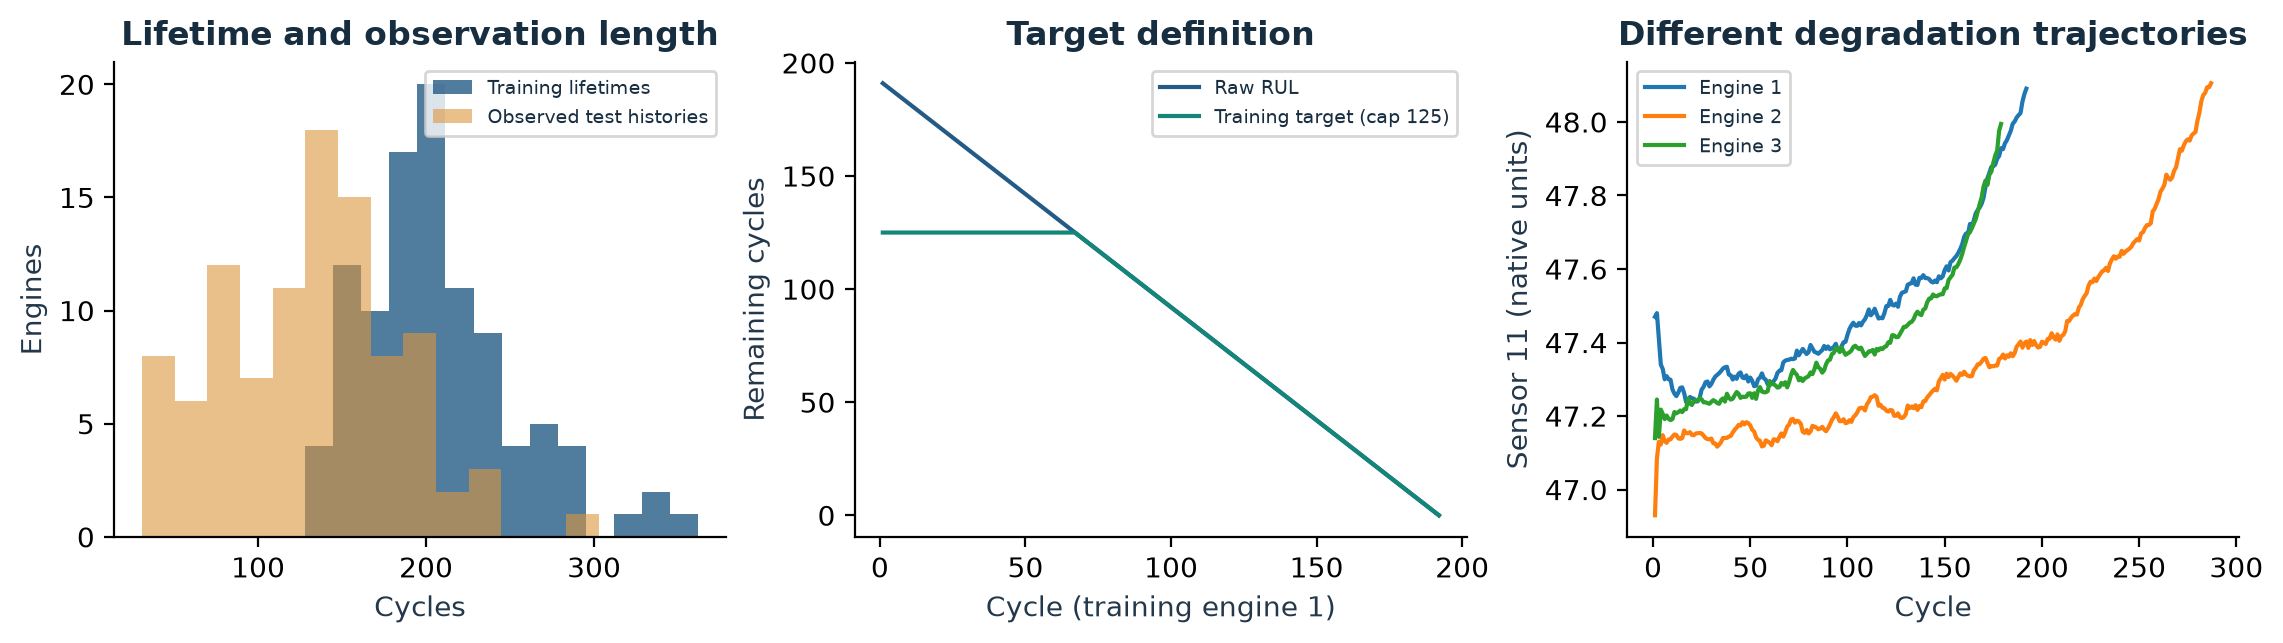

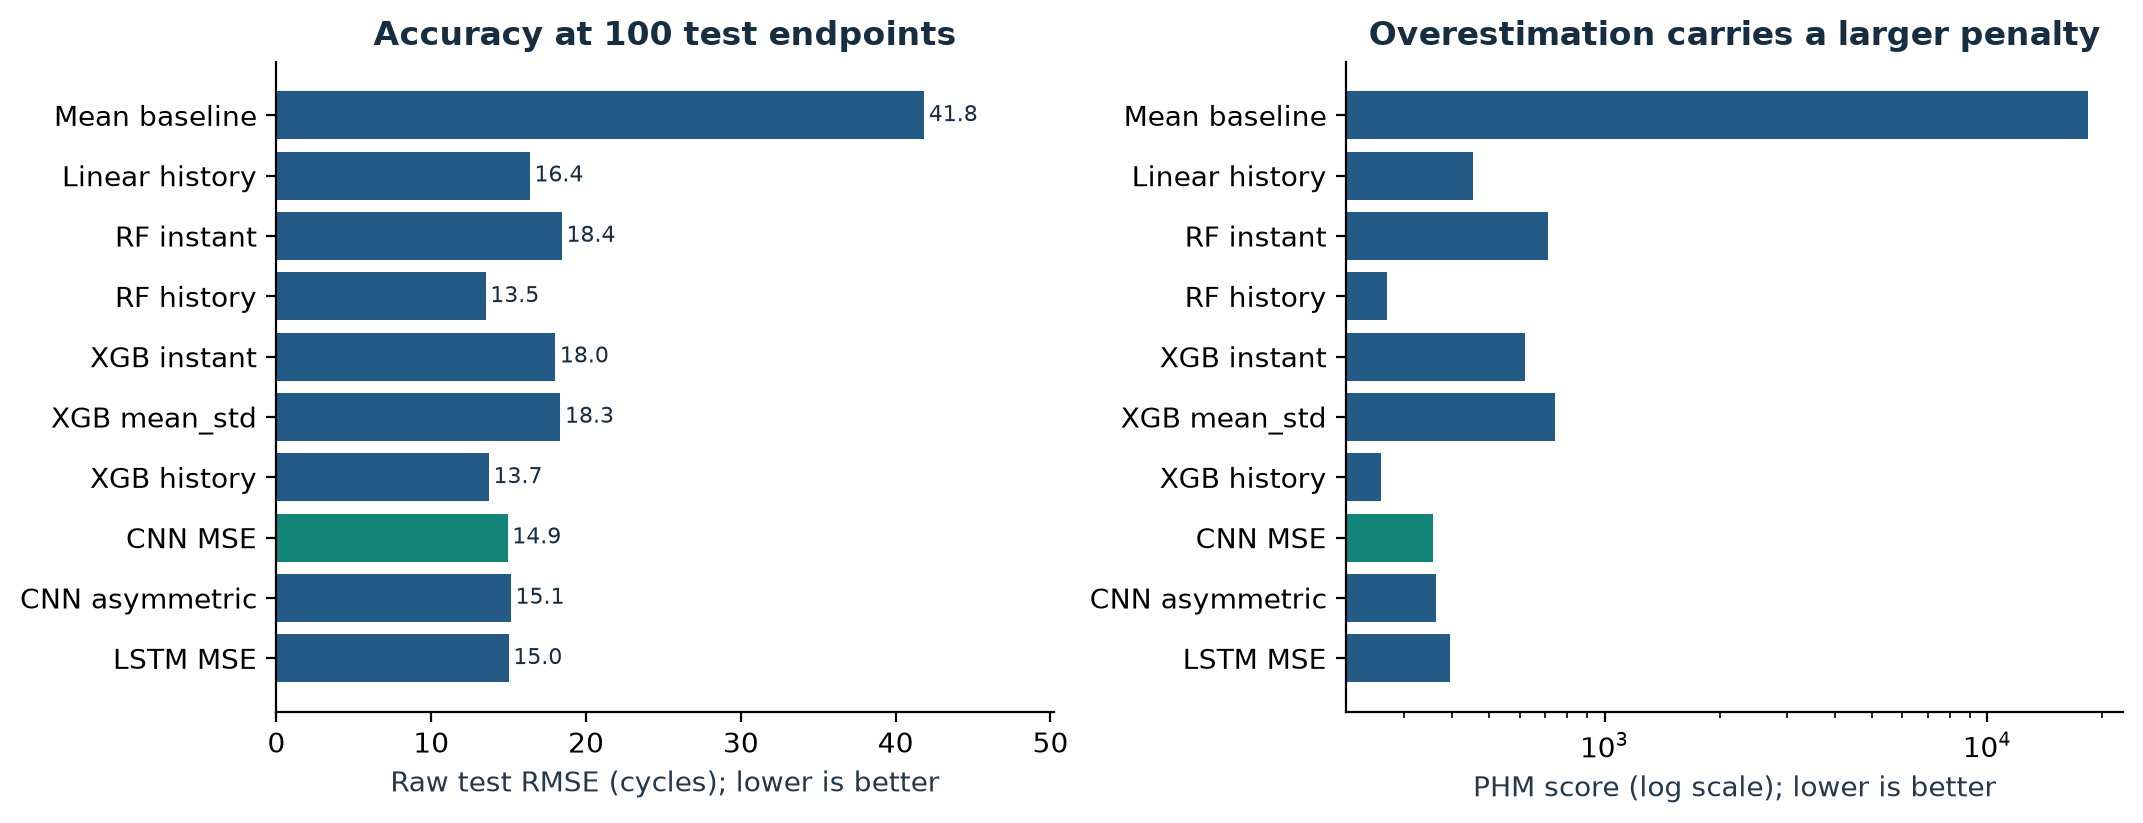

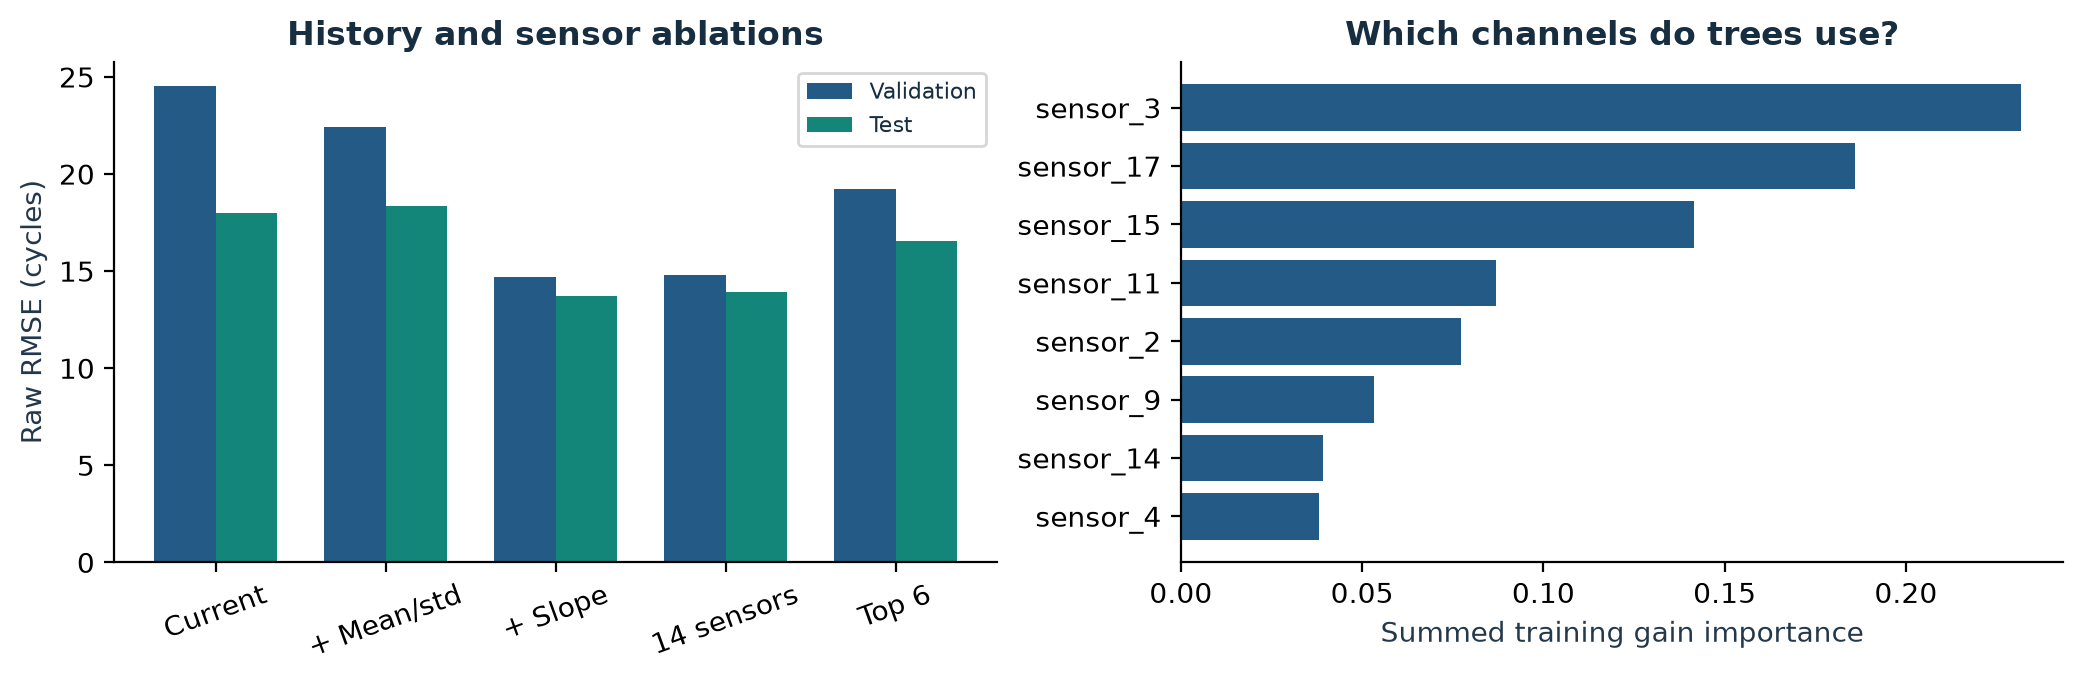

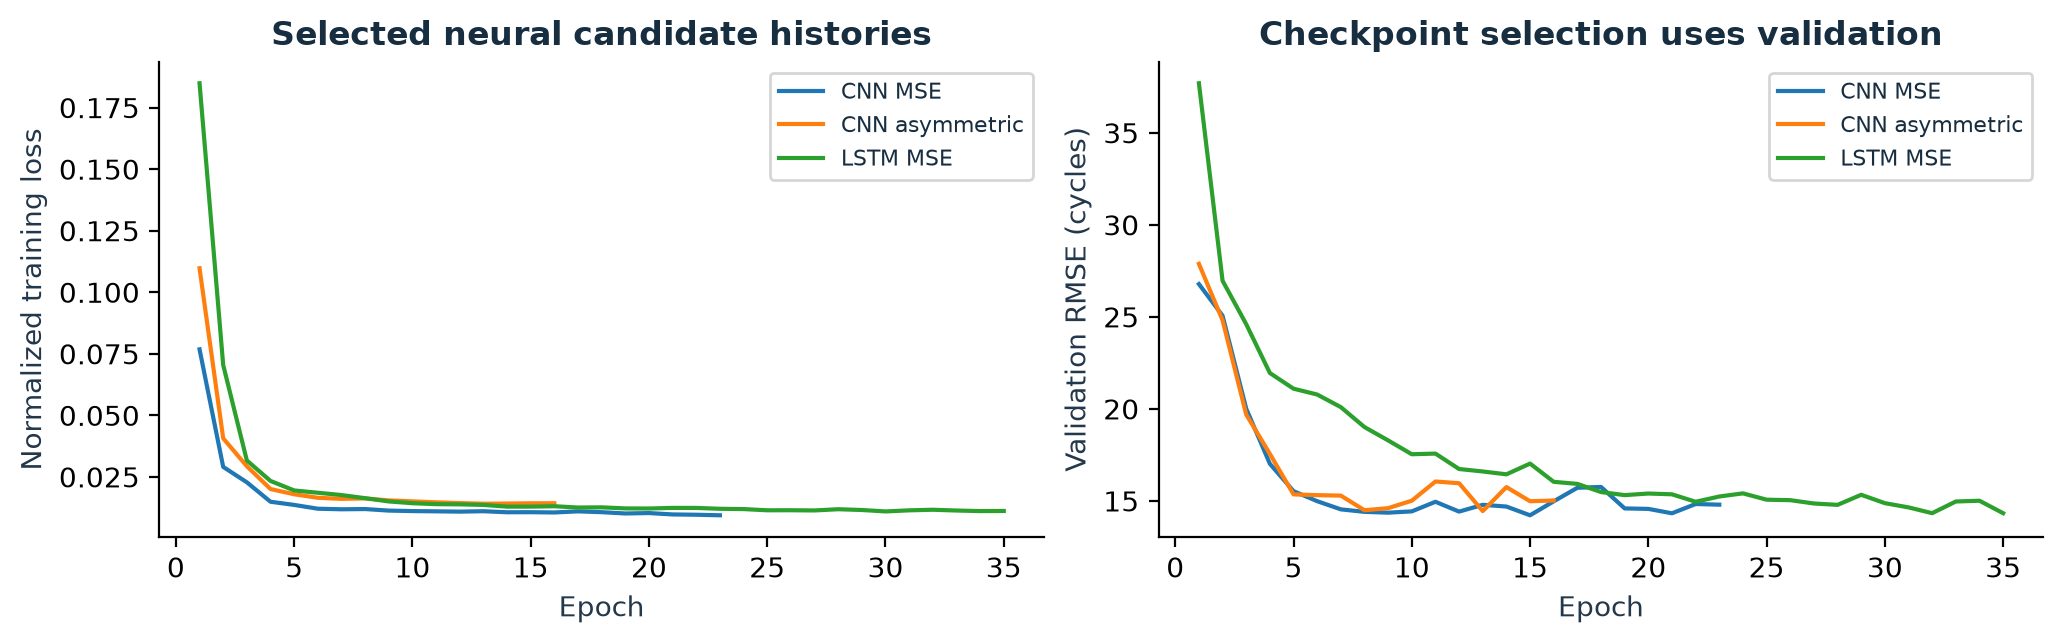

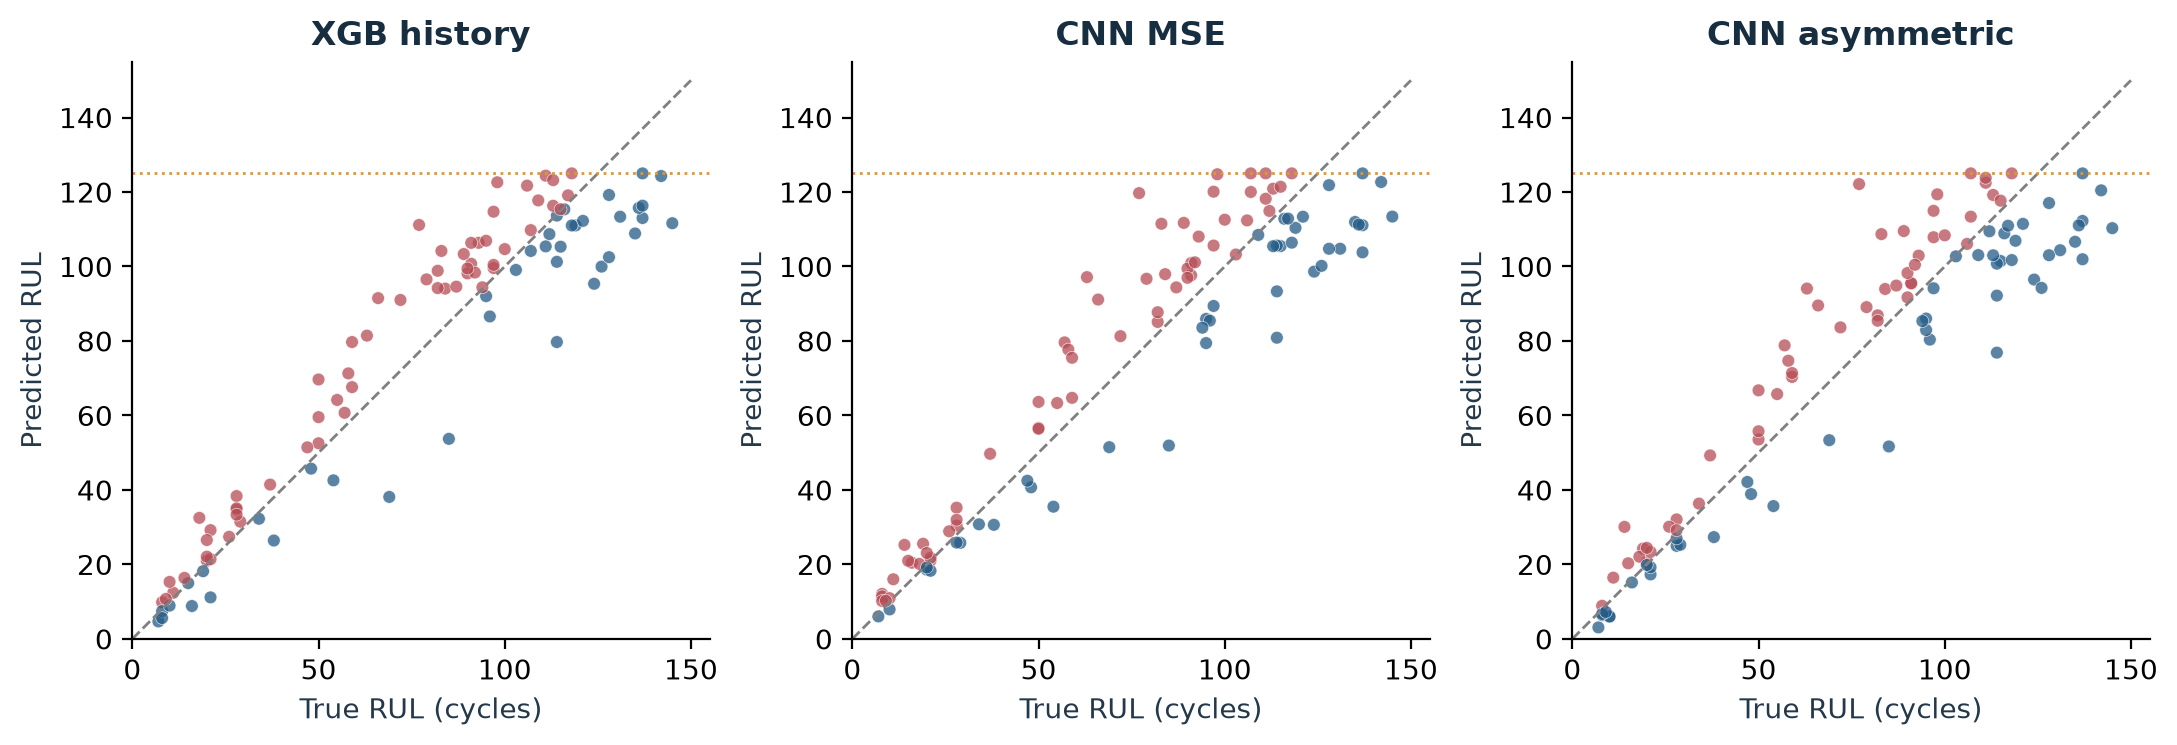

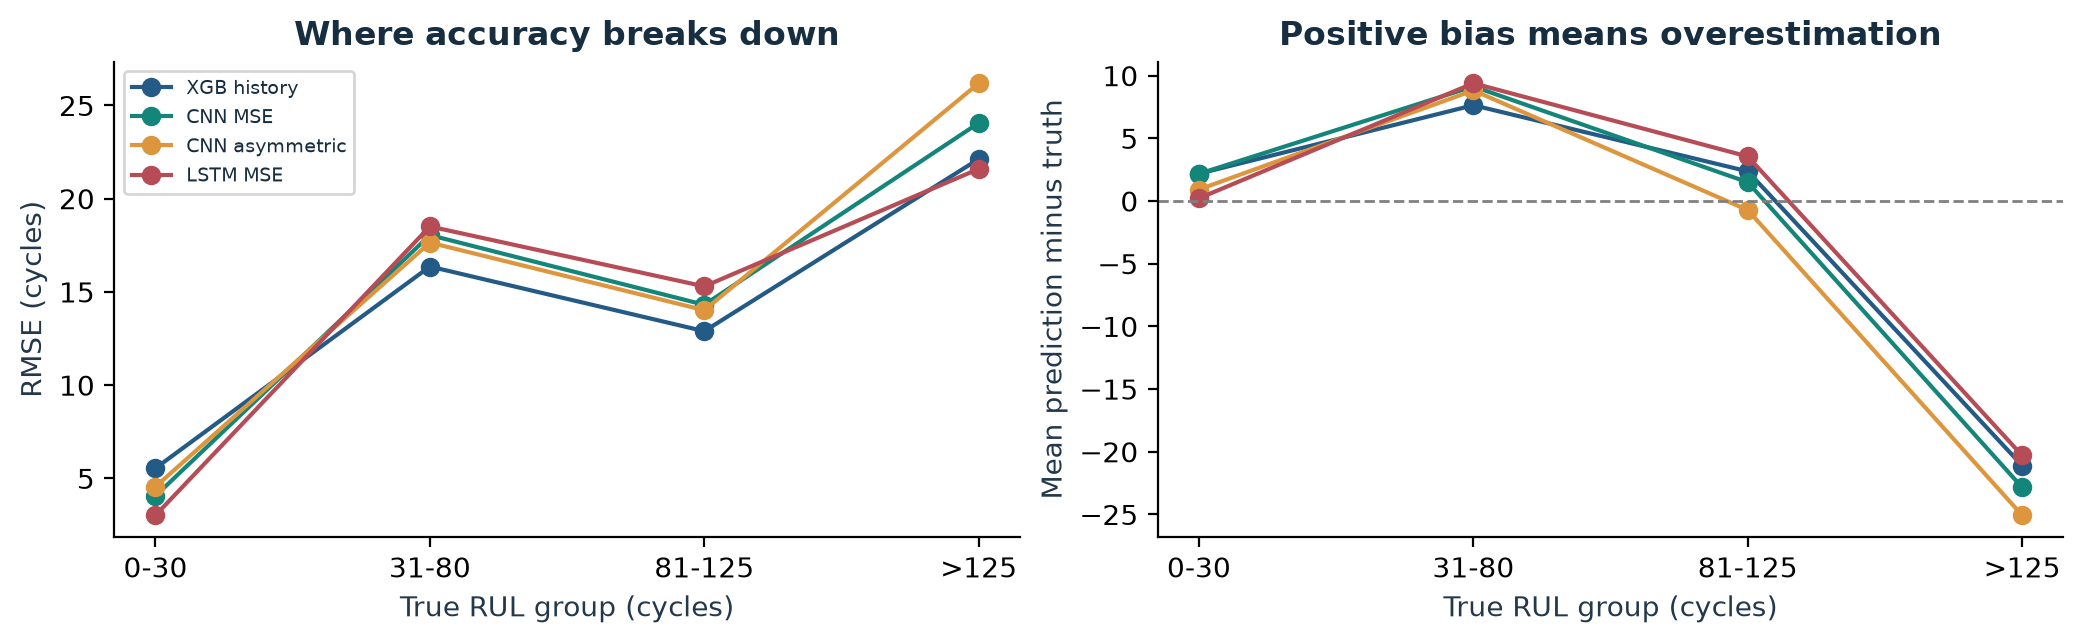

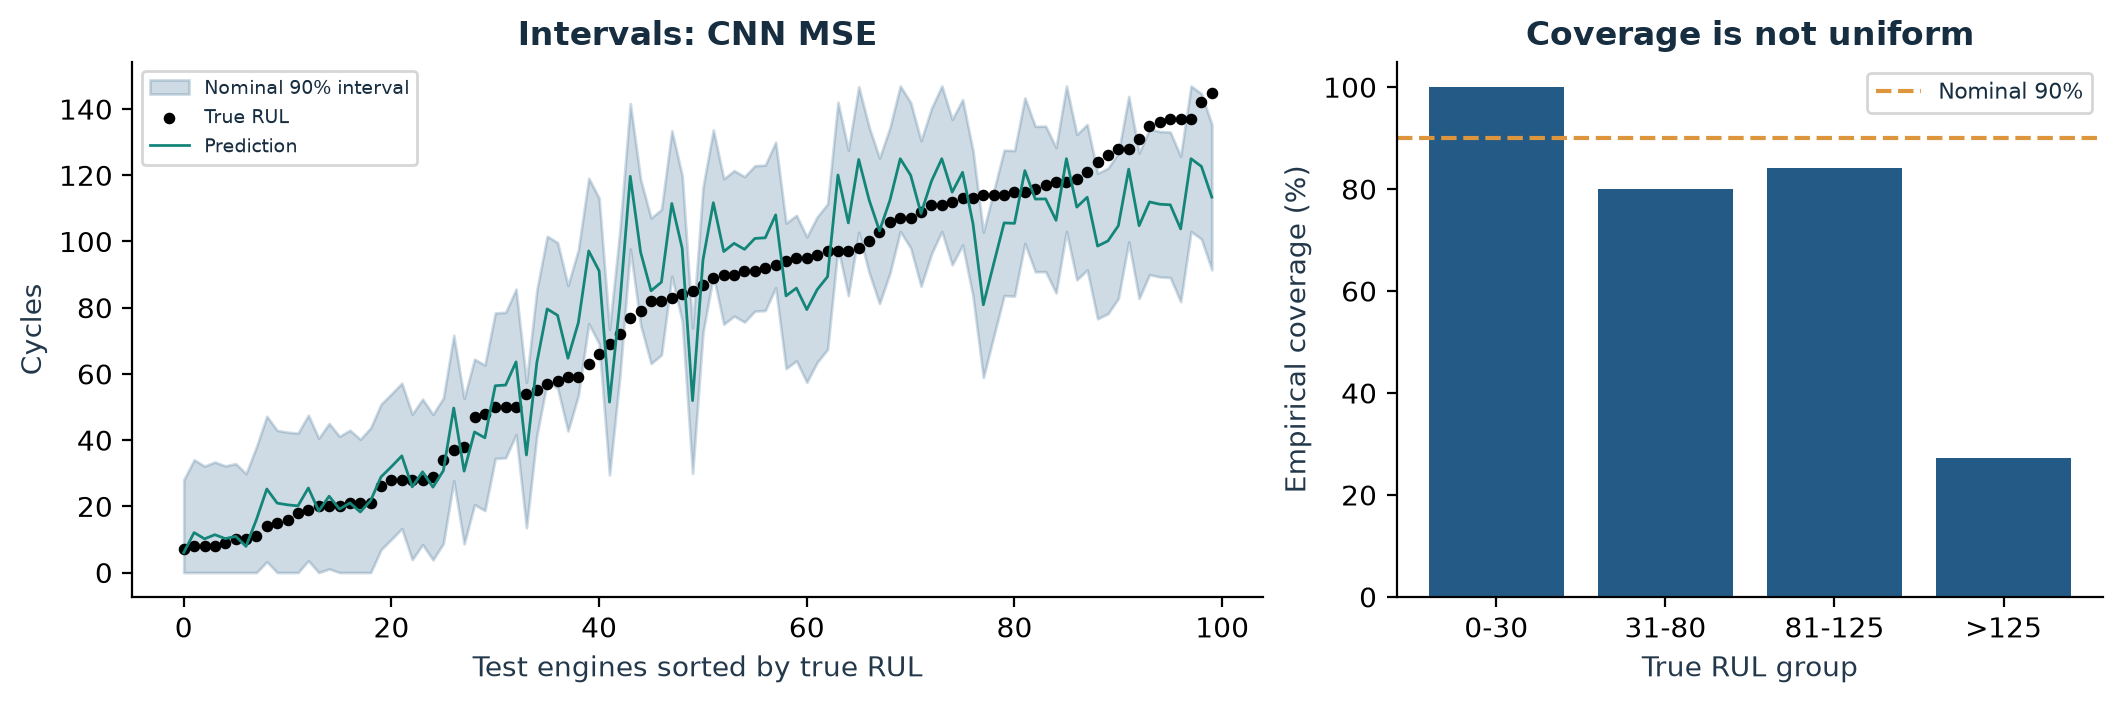

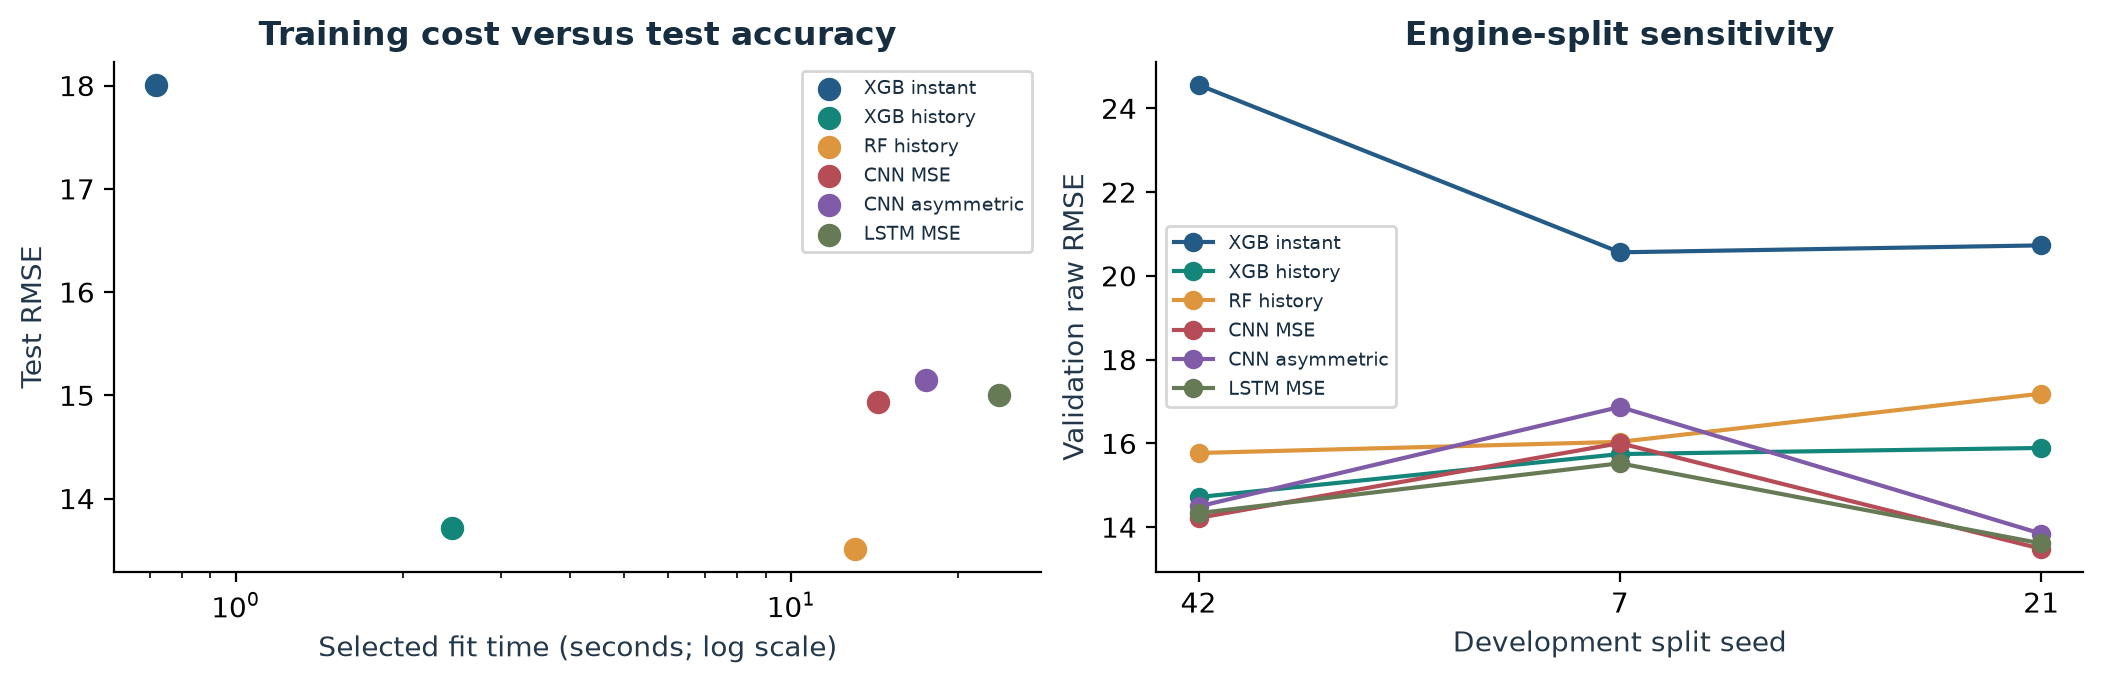

In [8]:
for name in ['dataset','model_comparison','ablations','learning_curves','failure_scatter','failure_stages','uncertainty','complexity_sensitivity']:
    display(Image(filename=str(ROOT/f'figures/{name}.png'),width=1000))

In [9]:
predictions=pd.read_csv(ROOT/'artifacts/test_predictions.csv')
chosen=manifest['selected_model']
errors=predictions.assign(error=predictions[chosen]-predictions.true_rul)
display(errors[['unit_id','endpoint','true_rul',chosen,'error']].reindex(errors.error.abs().sort_values(ascending=False).index).head(10))
display(pd.read_csv(ROOT/'artifacts/stage_metrics.csv').round(3))
print('Interpretation and limitations: see Final_Report.pdf, sections 5-6.')

,unit_id,endpoint,true_rul,CNN MSE,error
66,67,71,77.0,119.695540,42.695540
78,79,101,63.0,97.139280,34.139280
95,96,97,137.0,103.795395,-33.204605
44,45,152,114.0,80.878680,-33.121320
92,93,244,85.0,51.920433,-33.079567
24,25,48,145.0,113.400620,-31.599380
14,15,76,83.0,111.476710,28.476710
1,2,49,98.0,124.765850,26.765850
72,73,112,131.0,104.768550,-26.231450
54,55,113,137.0,111.082890,-25.917110


,model,stage,rmse,mae,phm,bias,over_rate,over_20_rate,n,coverage90
0,Mean baseline,0-30,63.056,62.632,16809.886,62.632,1.000,1.000,25,0.840
1,Mean baseline,31-80,27.163,24.252,425.365,24.252,1.000,0.700,20,1.000
2,Mean baseline,81-125,25.220,22.034,314.168,-22.034,0.000,0.000,44,1.000
3,Mean baseline,>125,54.672,54.375,782.375,-54.375,0.000,0.000,11,1.000
4,Linear instant,0-30,21.971,17.267,526.562,16.289,0.880,0.280,25,0.880
5,Linear instant,31-80,20.778,17.500,186.212,17.096,0.950,0.400,20,1.000
6,Linear instant,81-125,18.184,14.363,204.488,-7.200,0.295,0.068,44,0.977
7,Linear instant,>125,31.497,28.051,145.765,-28.051,0.000,0.000,11,0.636
8,XGB instant,0-30,14.413,9.807,114.106,7.493,0.600,0.200,25,1.000
9,XGB instant,31-80,19.260,12.634,245.133,9.382,0.600,0.350,20,0.900


Interpretation and limitations: see Final_Report.pdf, sections 5-6.


### Reproduce figures, documents, and regression checks
After a full rerun, execute `python scripts/make_figures.py` and `python scripts/build_report.py` to regenerate the figures and final report from the new artifacts. Run `python -m pytest -q` for leakage-boundary, metric-direction, window/label, short-history, feature-slope, shape, and calibration-quantile tests. Use `python scripts/predict.py test_FD001.txt --output predictions.csv` for label-free inference. The complete figure and document generation code is included in the repository under `scripts/`. References are listed in the final report; data are credited to NASA Ames PCoE (Saxena and Goebel, 2008).